# 🐍 Python Foundations for AI
## Class 8 — Object-Oriented Python for AI Systems

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
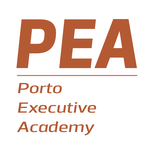
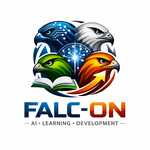
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | Why objects? |
| 2 | You already use objects every day |
| 3 | Class and object — template (blueprint) and thing |
| 4 | `__init__`, attributes, and `self` |
| 5 | Methods — giving an object something to do |
| 6 | Shared data, and keeping the inside inside |
| 7 | Inheritance — building on a class you already have |
| 8 | 🔗 Capstone — FALC-ON AI as two cooperating objects |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Explain what an object is, and recognise one when you read code
- Write a class with its own data and its own behaviour
- Keep an object's internal workings hidden behind simple methods
- Read and write `class Something(SomethingElse):`
- Build an AI assistant from objects that work together

### 🤖 Why AI code needs objects

By Class 7, FALC-ON AI was made of loose pieces: a `knowledge` dictionary, functions like `find_answer()`, and a database `connection` and `cursor`. Nothing in the code says these pieces belong together.

Real AI applications are **systems**: an assistant, its memory, its feedback — each one a separate part. Today you learn to build each part as an **object**, and to make the objects work together.

---
## 1. Why Objects?

Variables plus functions work well for a script. It starts to hurt when several values belong together. Here is one assistant, as loose variables:

In [ ]:
name = "FALC-ON AI"
model = "falcon-mini"
history = []

print(name, "uses", model)

A second assistant needs a second set — `name_2`, `model_2`, `history_2` — and every function needs all of them passed in, in the right order. Nothing stops you mixing `name` with `model_2`.

An **object** is one thing that holds both:

| | Called | Example |
|---|--------|---------|
| its **data** | attributes | the name, the model, the history |
| its **behaviour** | methods | answer a question, count the messages |

So instead of three loose variables, you have one `falcon` that knows its own data **and** what it can do.

> 💡 You are not obliged to use classes: a short script is often clearer without them. Reach for a class when you notice yourself passing the same three or four values into every function — that is the signal.

---
## 2. You Already Use Objects Every Day

Every value in Python is an object. A string, a list, a DataFrame — each one carries its own data **and** its own methods.

- `type(x)` tells you what **kind** of object `x` is — its **class**
- `x.lower()` calls a **method** that belongs to that object

In [ ]:
question = "What Is Python?"

print(type(question))            # type: str - question is a str object
print(question.lower())          # a method that belongs to this object

In [ ]:
history = ["hi"]

print(type(history))             # type: list
history.append("what is python?")    # a method that changes THIS list
print(history)

### Two objects of the same class, each with its own data

In [ ]:
ana_history = ["hi"]
bruno_history = ["hello"]

ana_history.append("what is colab?")

print(ana_history)
print(bruno_history)             # appending to one did nothing to the other

You have been doing this since Class 1. Today you build **your own** kind of object.

---
## 3. Class and Object — Template (Blueprint) and Thing

| Word | What it is | Analogy |
|------|-----------|---------|
| **Class** | a **template** (or blueprint): what every one of these has and can do | a document template — or the blueprint of a house |
| **Object** | one actual thing made from the template, with its own data | a document made from that template — or a house built from that blueprint |

One class, as many objects as you like — and each keeps its **own** values:

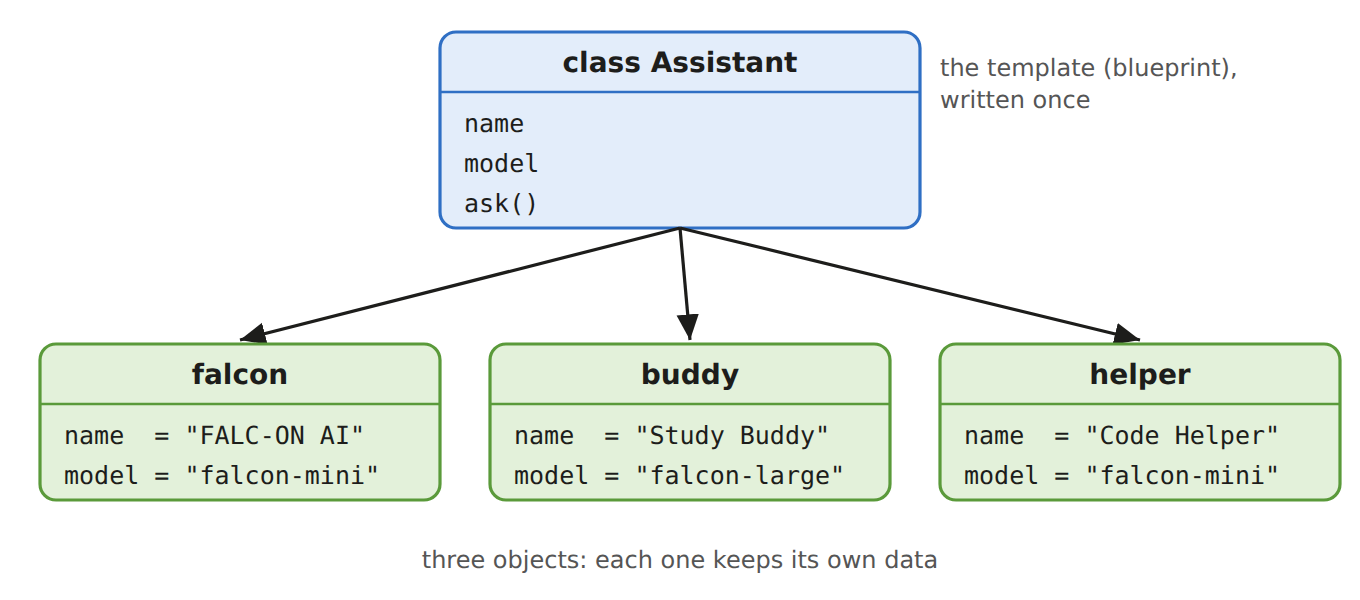

Making an object from a class is called **creating an instance**, and you do it by calling the class like a function: `Assistant("FALC-ON AI", "falcon-mini")`.

> 💡 Class names are written in `CapitalCase`: `Assistant`, not `assistant`. That is how you spot a class in someone else's code.

### The whole idea in one picture

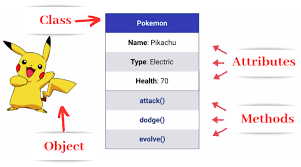

**Pokemon** is the class — what every Pokémon has and can do. **Pikachu** is an object built from it. Its **attributes** are the data it carries (a name, a type, a health value), and its **methods** are what it can do (attack, dodge, evolve).

Our `Assistant` has the same shape: a name and a model instead of a type and health; `answer()` instead of `attack()`.

---
## 4. `__init__`, Attributes, and `self`

Three new things, and they always appear together:

| Piece | What it is |
|-------|-----------|
| `__init__` | a method that **runs automatically** when you create an object. Its job is to store the starting data |
| `self` | **this particular object** — the one being built, or worked on, right now |
| `self.name = name` | store a value **on the object**, where it stays |

Read `self` as *"my own"*: `self.name` means *this assistant's* name. Every method takes `self` first, and **Python passes it for you** — you never write it when you call.

> ⚠️ `self.name = name` and `name = name` are completely different. The first stores the value **on the object**. The second makes a variable that vanishes when `__init__` ends — and you get an object with nothing in it.

In [ ]:
class Assistant:
    def __init__(self, name, model):
        self.name = name             # store it ON this object
        self.model = model

In [ ]:
# Creating objects - __init__ runs automatically each time
falcon = Assistant("FALC-ON AI", "falcon-mini")
buddy = Assistant("Study Buddy", "falcon-large")

print(falcon.name, "uses", falcon.model)
print(buddy.name, "uses", buddy.model)
print(type(falcon))              # type: Assistant - our own kind of object

### Each object keeps its own data

In [ ]:
buddy.name = "Exam Buddy"

print(falcon.name)               # FALC-ON AI - unchanged
print(buddy.name)                # Exam Buddy

---
## 5. Methods — Giving an Object Something to Do

A **method** is a function written **inside** a class. It takes `self` first, which is how it reaches the object's own data.

The gain over a function: the method already has the data.

```
find_answer(question, knowledge)     a function: you pass everything in
falcon.answer(question)              a method: the object already has its knowledge
```

Our assistant now gets a `knowledge` dictionary. The stand-in model from Class 4 becomes its `answer()` method, and a second method, `learn()`, **changes** the object's own data.

In [ ]:
class Assistant:
    def __init__(self, name, knowledge):
        self.name = name
        self.knowledge = knowledge

    def answer(self, question):
        """The stand-in model: answer from this assistant's own knowledge."""
        for keyword in self.knowledge:
            if keyword in question:
                return self.knowledge[keyword]
        return "Sorry, I don't know that yet."

    def learn(self, keyword, reply):
        """Add one answer to this assistant's knowledge."""
        self.knowledge[keyword] = reply

Two assistants, one class, **different knowledge**:

In [ ]:
course_knowledge = {
    "class": "The course has 10 classes.",
    "colab": "We write our code in Google Colab.",
}
python_knowledge = {
    "list": "A list keeps values in order.",
    "dict": "A dictionary maps keys to values.",
}

falcon = Assistant("FALC-ON AI", course_knowledge)
buddy = Assistant("Study Buddy", python_knowledge)

print(falcon.answer("how many classes are there?"))
print(buddy.answer("what is a dict?"))
print(buddy.answer("how many classes are there?"))     # not in buddy's knowledge

### A method that changes the object

In [ ]:
print(buddy.answer("what is a tuple?"))
buddy.learn("tuple", "A tuple is a list that cannot be changed.")
print(buddy.answer("what is a tuple?"))

---
## 6. Shared Data, and Keeping the Inside Inside

### Data that belongs to every object

An attribute set with `self.` in `__init__` belongs to **one** object. A variable written straight in the class body — a **class variable** — is **shared by all of them**. Use it for things true of the whole class: a limit, a label, a version. Read it as `Assistant.course`.

### Keeping the inside inside — encapsulation

**Encapsulation** means: keep an object's data and the methods that manage it together, and hide the details behind a few simple methods.

Python has no truly private data, but there is a strong convention: a name starting with an **underscore** — `self._history` — means *"internal, please don't touch this from outside"*. Other code goes through methods instead.

> 💡 **The payoff is freedom to change your mind.** If no code outside the class touches `_history`, you can later keep the history in a database instead of a list, and no other code breaks. The capstone does exactly that.

In [ ]:
class Assistant:
    course = "Python Foundations for AI"       # shared by EVERY assistant

    def __init__(self, name, knowledge):
        self.name = name
        self.knowledge = knowledge
        self._history = []                      # internal - note the underscore

    def answer(self, question):
        """The stand-in model: answer from this assistant's own knowledge."""
        for keyword in self.knowledge:
            if keyword in question:
                return self.knowledge[keyword]
        return "Sorry, I don't know that yet."

    def ask(self, question):
        """Answer a question, and remember both messages."""
        reply = self.answer(question)           # a method using another method
        self._history.append({"role": "user", "content": question})
        self._history.append({"role": "assistant", "content": reply})
        return reply

    def message_count(self):
        """How many messages are in the history."""
        return len(self._history)

    def history(self):
        """A copy of the history - safe to read from outside."""
        return list(self._history)

Every assistant sees the same class variable:

In [ ]:
falcon = Assistant("FALC-ON AI", course_knowledge)
buddy = Assistant("Study Buddy", python_knowledge)

print(falcon.course)
print(buddy.course)
print(Assistant.course)          # read it from the class itself

The outside world only uses `ask()`, `message_count()` and `history()`:

In [ ]:
print(falcon.ask("how many classes are there?"))
print(falcon.ask("do we use colab?"))
print("Messages:", falcon.message_count())

In [ ]:
for message in falcon.history():
    print(f"{message['role']}: {message['content']}")

---
## 7. Inheritance — Building on a Class You Already Have

We want a friendlier assistant that ends every answer with an emoji. Everything **else** is identical to `Assistant`.

**Inheritance** lets a new class start from an existing one, and change only what differs:

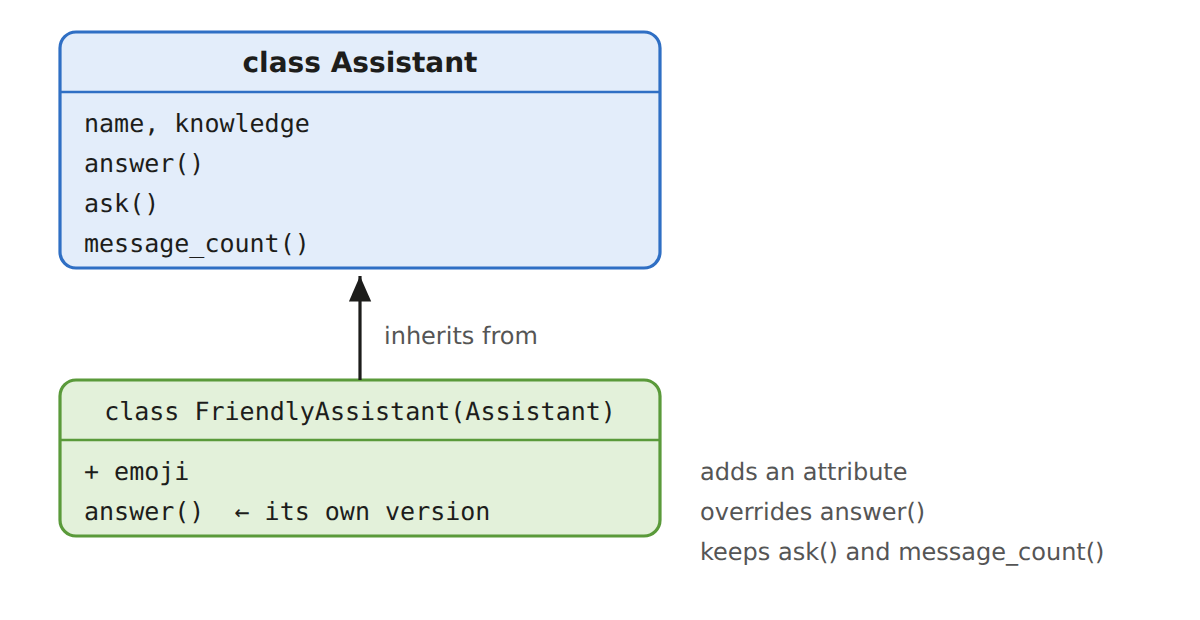

| Piece | Means |
|-------|-------|
| `class FriendlyAssistant(Assistant):` | start from `Assistant` — the **parent**, in brackets |
| `super().__init__(name, knowledge)` | run the parent's set-up, so you don't repeat it |
| Writing `answer()` again | **overriding** — this class's version wins |
| `super().answer(question)` | call the parent's version from inside the new one |
| Everything not written again | inherited unchanged, for free |

> ⚠️ **When not to use it.** Inheritance is for *"this is a kind of that"*: a friendly assistant **is** an assistant. If two classes merely share some code, that is not inheritance — reaching for it to avoid retyping is the most common way object-oriented code goes wrong.

> 💡 You will **read** this far more often than you write it. AI libraries are built this way, so `class Something(SomethingElse):` should become a sentence you understand at a glance.

In [ ]:
class FriendlyAssistant(Assistant):                  # starts from Assistant
    def __init__(self, name, knowledge, emoji):
        super().__init__(name, knowledge)            # let Assistant do its own set-up
        self.emoji = emoji                           # then add what is new

    def answer(self, question):                      # overriding: this version wins
        """The parent's answer, with an emoji at the end."""
        reply = super().answer(question)
        return f"{reply} {self.emoji}"

In [ ]:
sunny = FriendlyAssistant("Sunny", course_knowledge, "😊")

print(sunny.ask("do we use colab?"))       # ask() is inherited - and uses sunny's answer()
print("Messages:", sunny.message_count())  # inherited too
print(isinstance(sunny, Assistant))        # True - a FriendlyAssistant IS an Assistant

### One loop, and each object does the right thing

Both kinds of assistant have an `answer()` method, so one loop can use them all:

In [ ]:
assistants = [falcon, sunny]

for assistant in assistants:
    print(assistant.name, "->", assistant.answer("how many classes are there?"))

> 💡 When different objects answer the same call in their own way, that is called **polymorphism**. Now you know the word.

---
## 8. 🔗 Capstone — FALC-ON AI as Two Cooperating Objects

In Class 7 FALC-ON AI saved every turn in SQLite, with loose functions and a loose `cursor`. Now the same program is **two objects**, each with one job:

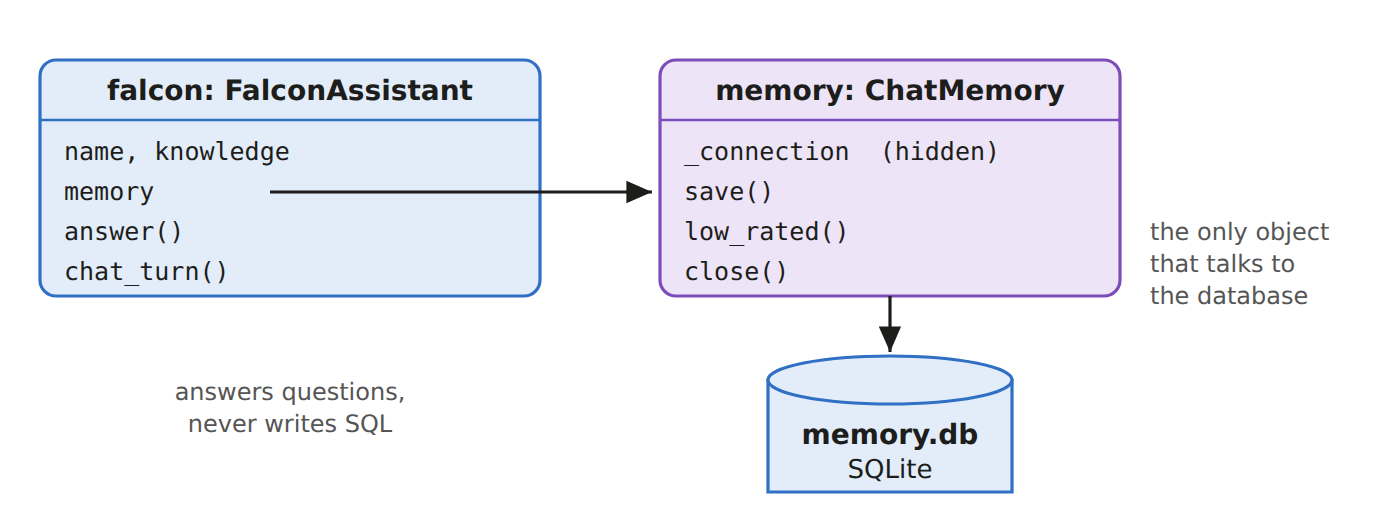

| Object | Its job | What it hides |
|--------|---------|---------------|
| `ChatMemory` | saves turns and answers questions about them | the connection, the cursor, all the SQL |
| `FalconAssistant` | answers questions, and hands each turn to its memory | nothing — it simply uses `memory.save()` |

This is how real AI systems are built — and the shape your final project will take.

### Step 1 — `ChatMemory`: the only object that talks to the database

The Class 7 code, moved inside a class. The connection and cursor start with `_`: nobody outside needs them.

In [ ]:
import sqlite3

class ChatMemory:
    """Long-term memory for an assistant, kept in a SQLite table."""

    def __init__(self, filename):
        self._connection = sqlite3.connect(filename)
        self._cursor = self._connection.cursor()
        self._cursor.execute("""
            CREATE TABLE IF NOT EXISTS memory (
                id       INTEGER PRIMARY KEY,
                user     TEXT,
                question TEXT,
                answer   TEXT,
                rating   INTEGER
            )
        """)
        self._cursor.execute("DELETE FROM memory")    # start clean, so re-running is safe
        self._connection.commit()

    def save(self, user, question, answer, rating):
        """Save one conversation turn."""
        self._cursor.execute(
            "INSERT INTO memory (user, question, answer, rating) VALUES (?, ?, ?, ?)",
            (user, question, answer, rating),
        )
        self._connection.commit()

    def low_rated(self):
        """The turns rated below 3 - the answers to improve."""
        self._cursor.execute("SELECT user, question, answer FROM memory WHERE rating < 3")
        return self._cursor.fetchall()

    def close(self):
        """Let go of the database file."""
        self._connection.close()

### Step 2 — `FalconAssistant`: answers, and hands every turn to its memory

The assistant is given a `ChatMemory` object when it is created, and keeps it as an attribute. An attribute can hold **any** object — even another object you built.

In [ ]:
class FalconAssistant:
    """FALC-ON AI: answers from its knowledge, and remembers every turn."""

    def __init__(self, name, knowledge, memory):
        self.name = name
        self.knowledge = knowledge
        self.memory = memory                    # another object - the two cooperate

    def answer(self, question):
        """The stand-in model: answer from the knowledge dictionary."""
        for keyword in self.knowledge:
            if keyword in question:
                return self.knowledge[keyword]
        return "Sorry, I don't know that yet."

    def chat_turn(self, user, question, rating):
        """Clean the question, answer it, and save the turn in memory."""
        question = question.lower().strip()
        reply = self.answer(question)
        self.memory.save(user, question, reply, rating)
        return reply

### Step 3 — Build the objects, and chat

Here the user's rating is given with the question, so the whole conversation runs without typing.

In [ ]:
knowledge = {
    "class": "The course has 10 classes.",
    "teach": "Alexandra Oliveira and Catarina Santos teach this course.",
    "colab": "We write our code in Google Colab.",
}

memory = ChatMemory("memory.db")
falcon = FalconAssistant("FALC-ON AI", knowledge, memory)

In [ ]:
print(falcon.chat_turn("ana", "How many classes are there?", 5))
print(falcon.chat_turn("ana", "Is there homework?", 2))
print(falcon.chat_turn("bruno", "  Who TEACHES this course? ", 4))
print(falcon.chat_turn("bruno", "When is the exam?", 1))

### Step 4 — Learn from the feedback

We ask the **memory** — without a single line of SQL out here.

In [ ]:
for user, question, answer in memory.low_rated():
    print(f"{user}: {question} -> {answer}")

### Step 5 — Close the memory

In [ ]:
memory.close()
print("Memory closed.")

> 💡 **Why this is better than Class 7:** `FalconAssistant` never mentions SQL. Replace `ChatMemory` with another class that has the same `save()` method — one that keeps a list, or talks to a cloud database — and `FalconAssistant` does not change by a single line. You will build exactly that in Exercise D2.

---

### 🎉 That's Class 8!

| Concept | Key syntax |
|---------|------------|
| Define a class | `class Assistant:` — `CapitalCase` |
| Set-up method | `def __init__(self, name, model):` |
| This object | `self` |
| Store data on it | `self.name = name` |
| Create an object | `falcon = Assistant("FALC-ON AI", "falcon-mini")` |
| Method | `def answer(self, question):` — called as `falcon.answer("...")` |
| Shared by all objects | `course = "..."` in the class body, read as `Assistant.course` |
| Internal, hands off | `self._history` — read it through a method |
| Inherit | `class FriendlyAssistant(Assistant):` |
| Reuse the parent | `super().__init__(...)`, `super().answer(...)` |
| Override | write the method again in the child class |
| Is it one of those? | `isinstance(sunny, Assistant)` |
| Objects that cooperate | an attribute holding another object: `self.memory = memory` |

> ⚠️ **The three that will catch you:** forgetting `self` as the first parameter of a method; writing `name = name` instead of `self.name = name` in `__init__`; passing `self` yourself when you call a method.

> 🤖 **The big picture:** FALC-ON AI is now a system of objects: an assistant that answers, and a memory that stores and reports. Every AI library you will use — including the one in Class 9 — is built from classes like these.

➡️ Now open the **exercises notebook**.